# Clase 10 — Panorama de modelos

**Laboratorio de Modelo Analítico para la Toma de Decisiones**
ISTEA · 2026-2C · División A

---

Arranca la unidad 3. Hoy **no vamos a entrenar nada en serio**: vamos a entender qué
significa que un modelo funcione, y a construir las dos referencias contra las que se
compara todo lo que viene.

| Parte | Qué es | Cuándo |
| --- | --- | --- |
| **A** | La línea de base, una regla simple y el sobreajuste, sobre ElecCommSphere | Lo hacemos juntos |
| **B** | Los dos números de **tu** dataset | Segunda hora, en equipo |

> **Lo que te tenés que llevar:** dos números anotados. Cuánto se acierta sin modelo, y
> cuánto acierta tu mejor regla de una sola variable. Sin esos dos, cualquier porcentaje
> que reportes en el trabajo final no significa nada.

---
# PARTE A · ElecCommSphere

## A0 · La tabla de clientes de la clase 8

La reconstruimos de cero para que el notebook corra solo, pero es exactamente la misma
que armaron ustedes: una fila por cliente, nueve variables y la etiqueta.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
AZUL, GRIS, ROJO, VERDE = "#0A2FF1", "#6E7280", "#B4341F", "#1E7A46"

tx  = pd.read_csv("eleccommsphere_transacciones.csv", parse_dates=["fecha"])
cli = pd.read_csv("eleccommsphere_clientes.csv", parse_dates=["fecha_alta"])

t = tx.drop_duplicates()
t = t[t["id_cliente"].isin(cli["id_cliente"])]
t["categoria"] = (t["categoria"].str.strip().str.lower()
                    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8"))
t = t[t["monto"].notna() & (t["monto"] > 0)]
t = t[t["monto"] <= t["monto"].quantile(0.999)]

CORTE = pd.Timestamp("2026-03-31")
obs, post = t[t["fecha"] <= CORTE], t[t["fecha"] > CORTE]
g = obs.groupby("id_cliente")

X = pd.DataFrame({
    "recencia":   (CORTE - g["fecha"].max()).dt.days,
    "frecuencia": g.size(),
    "monto":      g["monto"].sum(),
    "ticket":     g["monto"].mean(),
    "antiguedad": (CORTE - g["fecha"].min()).dt.days,
    "categorias": g["categoria"].nunique(),
    "canales":    g["canal"].nunique(),
    "tasa_dev":   g["devuelto"].mean(),
})
X["intensidad"] = X["frecuencia"] / X["antiguedad"].clip(lower=1)
y = pd.Series((~X.index.isin(post["id_cliente"])).astype(int),
              index=X.index, name="churn")

print(f"Clientes : {len(X):,}")
print(f"Variables: {X.shape[1]}")
print(f"Abandono : {y.mean():.1%}")

Clientes : 3,066
Variables: 9
Abandono : 45.6%


## A1 · La línea de base

**Antes de entrenar nada**, la pregunta es: ¿cuánto se acierta sin modelo?

El modelo más tonto posible es decir siempre lo mismo. Si el 45,6 % abandona, decir que
**no se va nadie** ya acierta el 54,4 % de las veces.

In [2]:
from sklearn.metrics import accuracy_score, roc_auc_score

nadie  = np.zeros(len(y))      # "no se va nadie"
todos  = np.ones(len(y))       # "se van todos"

print(f"Decir que NO se va nadie : {accuracy_score(y, nadie):.1%}")
print(f"Decir que se van TODOS   : {accuracy_score(y, todos):.1%}")

BASE = max(accuracy_score(y, nadie), accuracy_score(y, todos))
print(f"\n→ La línea de base es {BASE:.1%}. Cualquier modelo que no la supere, sobra.")

Decir que NO se va nadie : 54.4%
Decir que se van TODOS   : 45.6%

→ La línea de base es 54.4%. Cualquier modelo que no la supere, sobra.


> **Por qué esto importa tanto.** Es el error más común de los informes: alguien presenta
> «el modelo acierta el 85 %» y nadie pregunta cuánto se acertaba antes. Si el evento pasa
> en el 15 % de los casos, decir que nunca pasa ya acierta el 85 %.
>
> El AUC tiene la ventaja de que su línea de base siempre es la misma: **0,500 es tirar
> una moneda**, pase lo que pase con las proporciones.

## A2 · Una regla de una sola variable

Un modelo no tiene por qué ser complicado. «Se va si hace más de X días que no compra»
ya es un modelo, y se construye probando todos los cortes posibles.

Mejor umbral: 70 días → acierta 70.7%
AUC de la recencia sola: 0.756


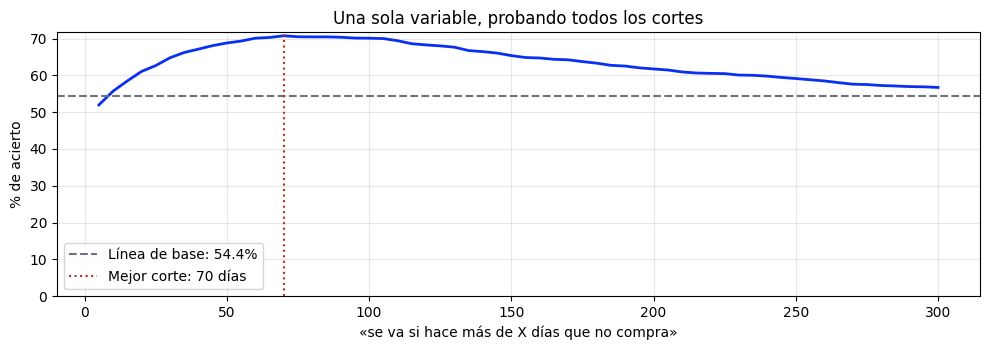

In [3]:
resultados = []
for u in range(5, 301, 5):
    pred = (X["recencia"] > u).astype(int)
    resultados.append({"umbral": u, "acierto": accuracy_score(y, pred)})

r = pd.DataFrame(resultados)
mejor = r.loc[r["acierto"].idxmax()]
print(f"Mejor umbral: {mejor['umbral']:.0f} días → acierta {mejor['acierto']:.1%}")
print(f"AUC de la recencia sola: {roc_auc_score(y, X['recencia']):.3f}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(r["umbral"], r["acierto"] * 100, color=AZUL, lw=2)
ax.axhline(BASE * 100, ls="--", color=GRIS, label=f"Línea de base: {BASE:.1%}")
ax.axvline(mejor["umbral"], ls=":", color=ROJO, label=f"Mejor corte: {mejor['umbral']:.0f} días")
ax.set_xlabel("«se va si hace más de X días que no compra»")
ax.set_ylabel("% de acierto"); ax.set_ylim(0, None); ax.legend()
ax.set_title("Una sola variable, probando todos los cortes")
plt.tight_layout(); plt.show()

Dieciséis puntos por encima de la base, con **una variable y un número**. Eso es el piso
real contra el que hay que comparar cualquier modelo que venga después.

## A3 · Partir en entrenamiento y prueba

Esta es una partición distinta de la de la clase 8. Allá partíamos **el tiempo** para no
usar el futuro; acá partimos **las filas** para no evaluar al modelo con lo que ya vio.

In [4]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(
    X, y,
    test_size=0.30,       # 30 % se guarda y no se toca
    random_state=42,      # para que sea reproducible
    stratify=y)           # misma proporción de abandono en las dos partes

print(f"Entrenamiento: {len(Xtr):,} clientes · abandono {ytr.mean():.1%}")
print(f"Prueba       : {len(Xte):,} clientes · abandono {yte.mean():.1%}")
print("\nLas proporciones coinciden: eso lo hace stratify.")

Entrenamiento: 2,146 clientes · abandono 45.6%
Prueba       : 920 clientes · abandono 45.5%

Las proporciones coinciden: eso lo hace stratify.


## A4 · El modelo completo

Regresión logística con las nueve variables. La vamos a ver en detalle en la clase 12;
hoy nos interesa solo el número que devuelve.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

modelo = Pipeline([
    ("escalar", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
]).fit(Xtr, ytr)

prob = modelo.predict_proba(Xte)[:, 1]
pred = modelo.predict(Xte)

print(f"Acierto en prueba: {accuracy_score(yte, pred):.1%}")
print(f"AUC en prueba    : {roc_auc_score(yte, prob):.3f}")

Acierto en prueba: 72.1%
AUC en prueba    : 0.772


## A5 · Los tres juntos

Acá está la tabla que importa de toda la clase.

In [6]:
regla_te = (Xte["recencia"] > mejor["umbral"]).astype(int)

comparacion = pd.DataFrame([
    {"modelo": "Decir que no se va nadie",
     "acierto": accuracy_score(yte, np.zeros(len(yte))), "auc": 0.500},
    {"modelo": f"Regla: recencia > {mejor['umbral']:.0f} días",
     "acierto": accuracy_score(yte, regla_te), "auc": roc_auc_score(yte, Xte["recencia"])},
    {"modelo": "Regresión logística, 9 variables",
     "acierto": accuracy_score(yte, pred), "auc": roc_auc_score(yte, prob)},
])
comparacion["sobre la base"] = (comparacion["acierto"] - comparacion["acierto"].iloc[0]) * 100
comparacion["acierto"] = (comparacion["acierto"] * 100).round(1)
comparacion["auc"] = comparacion["auc"].round(3)
comparacion["sobre la base"] = comparacion["sobre la base"].round(1)
comparacion

,modelo,acierto,auc,sobre la base
0,Decir que no se va nadie,54.5,0.500,0.0
1,Regla: recencia > 70 días,69.6,0.754,15.1
2,"Regresión logística, 9 variables",72.1,0.772,17.6


> **Lo que se ve acá.** Una sola variable con un umbral se lleva casi toda la mejora. El
> modelo completo, con nueve variables, agrega poco más de un punto de acierto.
>
> **No significa que el modelo no sirva.** El AUC sube, y en la clase 13 vamos a ver que
> esa diferencia chica puede valer bastante plata según el umbral que se elija. Pero
> conviene saber de dónde viene cada punto, y nunca presentar un modelo sin decir contra
> qué se lo comparó.

El grupo 9 hizo exactamente esto en su TP1 sin que nadie se lo pidiera: midió que su
señal acertaba el 69 % contra un piso de 65 %, y reportó la mejora de cuatro puntos.

## A6 · El error que da 100 %

Ahora el experimento que más vale la pena de la clase. Un árbol de decisión **sin límite
de profundidad**, sobre los mismos datos.

In [7]:
from sklearn.tree import DecisionTreeClassifier

arbol = DecisionTreeClassifier(random_state=42).fit(Xtr, ytr)

print("Árbol SIN límite de profundidad")
print(f"   acierto en ENTRENAMIENTO : {accuracy_score(ytr, arbol.predict(Xtr)):.1%}")
print(f"   acierto en PRUEBA        : {accuracy_score(yte, arbol.predict(Xte)):.1%}")
print(f"   profundidad que alcanzó  : {arbol.get_depth()} niveles")
print(f"   hojas                    : {arbol.get_n_leaves():,}")

Árbol SIN límite de profundidad
   acierto en ENTRENAMIENTO : 100.0%
   acierto en PRUEBA        : 64.0%
   profundidad que alcanzó  : 26 niveles
   hojas                    : 478


**Cien por ciento en entrenamiento.** Ni un error. Y en prueba acierta menos que la regla
de una sola variable.

No memorizó mal: memorizó demasiado bien. Con suficientes ramas, cualquier conjunto se
puede clasificar perfecto — aprendió cada cliente de memoria, incluido el ruido, y por eso
no sabe qué hacer con uno nuevo.

Esto se llama **sobreajuste**, y es la razón por la que existe el conjunto de prueba.

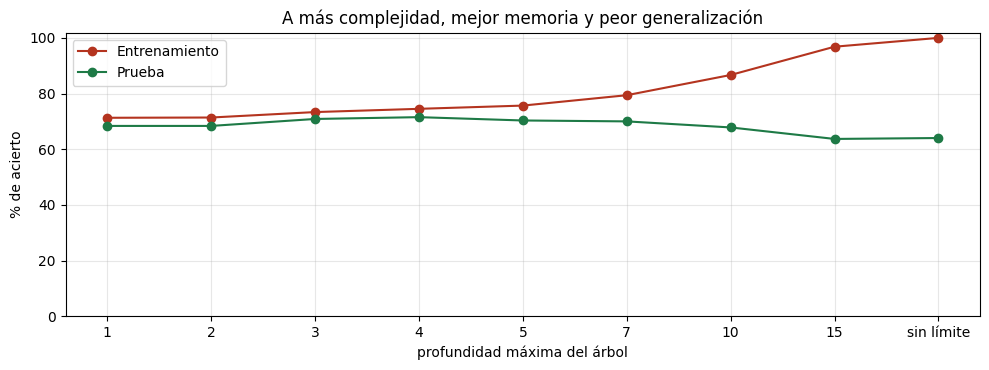

,profundidad,entrenamiento,prueba
0,1,71.3,68.4
1,2,71.4,68.4
2,3,73.3,70.9
3,4,74.5,71.5
4,5,75.7,70.3
5,7,79.4,70.0
6,10,86.7,67.8
7,15,96.8,63.7
8,sin límite,100.0,64.0


In [8]:
filas = []
for prof in [1, 2, 3, 4, 5, 7, 10, 15, None]:
    a = DecisionTreeClassifier(max_depth=prof, random_state=42).fit(Xtr, ytr)
    filas.append({"profundidad": prof if prof else "sin límite",
                  "entrenamiento": accuracy_score(ytr, a.predict(Xtr)),
                  "prueba": accuracy_score(yte, a.predict(Xte))})
prof_df = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = range(len(prof_df))
ax.plot(x, prof_df["entrenamiento"] * 100, marker="o", color=ROJO, label="Entrenamiento")
ax.plot(x, prof_df["prueba"] * 100, marker="o", color=VERDE, label="Prueba")
ax.set_xticks(list(x)); ax.set_xticklabels(prof_df["profundidad"])
ax.set_xlabel("profundidad máxima del árbol"); ax.set_ylabel("% de acierto")
ax.set_ylim(0, None); ax.legend()
ax.set_title("A más complejidad, mejor memoria y peor generalización")
plt.tight_layout(); plt.show()

prof_df.assign(entrenamiento=(prof_df.entrenamiento*100).round(1),
               prueba=(prof_df.prueba*100).round(1))

> **Las dos curvas se abren.** Mientras la roja sube hasta 100 y la verde se queda o baja,
> el modelo está memorizando en lugar de aprender.
>
> El punto donde la verde es más alta es la complejidad que conviene. Que el número de
> entrenamiento baje es **buena** señal: un modelo que anda casi igual en las dos partes
> es uno que aprendió algo general.

## A7 · Lo que devuelve un modelo: una probabilidad

Un modelo no dice «este se va». Dice «este tiene 0,81 de probabilidad de irse». Esa
diferencia es la que permite priorizar.

In [9]:
riesgo = pd.DataFrame({"prob": prob, "se_fue": yte.values}, index=Xte.index)
riesgo = riesgo.sort_values("prob", ascending=False)

print("Los diez clientes de mayor riesgo según el modelo:")
print(riesgo.head(10).assign(prob=lambda d: d["prob"].round(3)).to_string())

print(f"\nDe los 50 de mayor riesgo, se fueron: {riesgo.head(50)['se_fue'].sum()} de 50")
print(f"De los 50 de menor riesgo, se fueron: {riesgo.tail(50)['se_fue'].sum()} de 50")

Los diez clientes de mayor riesgo según el modelo:
             prob  se_fue
id_cliente               
2144        0.978       1
3174        0.971       1
1835        0.969       1
3818        0.967       0
862         0.965       1
1464        0.960       1
2344        0.958       1
3480        0.957       0
1423        0.957       1
712         0.953       1

De los 50 de mayor riesgo, se fueron: 41 de 50
De los 50 de menor riesgo, se fueron: 4 de 50


Esa es la utilidad real: **si el presupuesto alcanza para llamar a cincuenta clientes, se
llama a los cincuenta de arriba de la lista**, no a cincuenta cualquiera.

Convertir la probabilidad en un sí o un no exige elegir un umbral, y ese umbral no lo
elige el modelo: lo elige el negocio. Es la clase 13.

## A8 · Qué variable pesa

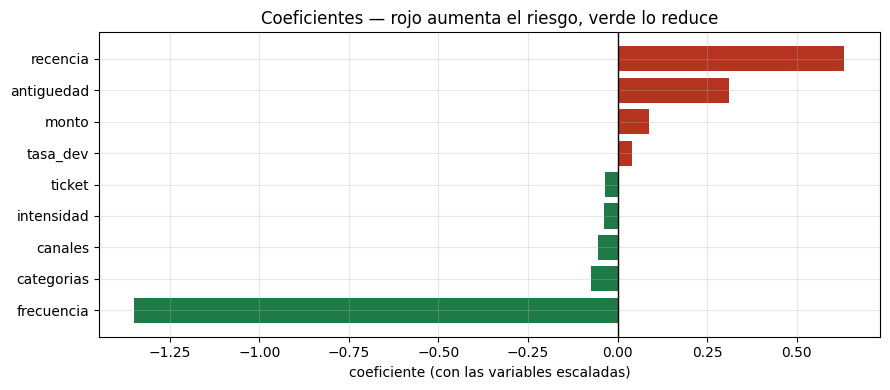

,coeficiente
frecuencia,-1.348
categorias,-0.073
canales,-0.054
intensidad,-0.037
ticket,-0.036
tasa_dev,0.041
monto,0.089
antiguedad,0.310
recencia,0.633


In [10]:
coef = pd.Series(modelo["clf"].coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
colores = [ROJO if v > 0 else VERDE for v in coef]
ax.barh(coef.index, coef.values, color=colores)
ax.axvline(0, color="k", lw=1)
ax.set_title("Coeficientes — rojo aumenta el riesgo, verde lo reduce")
ax.set_xlabel("coeficiente (con las variables escaladas)")
plt.tight_layout(); plt.show()

coef.round(3).to_frame("coeficiente")

> **Ojo con dos cosas.** Primero, estos números solo se pueden comparar entre sí porque
> las variables están escaladas; sin `StandardScaler` el coeficiente del monto sería
> diminuto solo por estar medido en pesos.
>
> Segundo, **un coeficiente no es una causa**. Que la frecuencia tenga el coeficiente más
> negativo no significa que forzar compras evite el abandono: significa que quien compra
> seguido es, además, quien tiende a quedarse.

---
# PARTE B · Tu dataset

## B0 · Cargá tu tabla de clientes

La de la clase 8, con una fila por cliente y la etiqueta.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score

# ── Cargá la tabla que guardaste en la clase 8 ───────────────────────────
# B = pd.read_csv("mi_tabla_clientes.csv", index_col=0)
# yB = B.pop("churn").astype(int)

# Mientras no la cargues, corre sobre ElecCommSphere
B, yB = X.copy(), y.copy()

print(f"Filas (una por cliente): {len(B):,}")
print(f"Variables              : {B.shape[1]}")
print(f"Proporción de la etiqueta positiva: {yB.mean():.1%}")

> **Si la etiqueta te da 0 % o 100 %**, la ventana de resultado está mal elegida y no hay
> nada que predecir. Volvé a la clase 8 y corré el corte.

## B1 · Tu línea de base

El primero de los dos números que te tenés que llevar.

In [ ]:
BASE_B = max(yB.mean(), 1 - yB.mean())
mayoritaria = "la etiqueta positiva" if yB.mean() > 0.5 else "la etiqueta negativa"

print(f"Proporción positiva : {yB.mean():.1%}")
print(f"LÍNEA DE BASE       : {BASE_B:.1%}   (decir siempre {mayoritaria})")
print(f"\nAUC de base         : 0,500")
print("\n→ Anotá este número. Es contra él que se compara todo lo que venga.")

## B2 · Tu mejor regla de una variable

El segundo número. Probamos todas las variables numéricas y todos los cortes razonables,
y nos quedamos con la combinación que más acierta.

In [ ]:
candidatas = [c for c in B.columns if pd.api.types.is_numeric_dtype(B[c]) and B[c].nunique() > 5]
print("Variables candidatas:", candidatas, "\n")

filas = []
for col in candidatas:
    v = B[col]
    for q in np.arange(0.05, 1.0, 0.05):
        u = v.quantile(q)
        for signo, pred in [(">", (v > u).astype(int)), ("<", (v < u).astype(int))]:
            filas.append({"variable": col, "signo": signo, "umbral": u,
                          "acierto": accuracy_score(yB, pred)})

reglas = pd.DataFrame(filas).sort_values("acierto", ascending=False)
top = reglas.head(8).copy()
top["acierto"] = (top["acierto"] * 100).round(1)
top["umbral"] = top["umbral"].round(2)
print("Las ocho mejores reglas de una sola variable:")
print(top.to_string(index=False))

best = reglas.iloc[0]
print(f"\nMEJOR REGLA: «{best['variable']} {best['signo']} {best['umbral']:.2f}»")
print(f"  acierta  : {best['acierto']:.1%}")
print(f"  base     : {BASE_B:.1%}")
print(f"  mejora   : {(best['acierto'] - BASE_B) * 100:+.1f} puntos")

> **Si la mejora es de menos de dos o tres puntos**, no está mal: significa que ninguna
> variable sola separa, y que va a hacer falta el modelo multivariado de la clase 12. Es
> un resultado, anotalo.
>
> **Si alguna regla acierta sospechosamente bien** —más del 90 %— revisá que esa variable
> no se haya construido con datos posteriores al corte. Es la fuga de información de la
> clase 8.

## B3 · Los dos números, anotados

Completá esta celda. Es lo que se entrega.

### Nuestros dos números

**Equipo:**
**Dataset:**

| | Valor |
| --- | --- |
| Línea de base (decir siempre lo mismo) | |
| Mejor regla de una variable | |
| La regla, escrita | |
| Mejora sobre la base | |

**Qué se predice en nuestro caso, en una oración:**

**Para qué decisión serviría:**

---

> Si concluyen que en su dataset no hace falta modelar —porque no hay acción posible con
> la respuesta, o porque la regla simple ya alcanza— escríbanlo acá con el argumento. Es
> una conclusión profesional válida y vale lo mismo que un modelo que funcione.

---
## Lo que se entrega esta semana

A Classroom antes de la clase 11:

- **los dos números**: la línea de base y el acierto de su mejor regla, con la variable
  y el umbral que usaron,
- **una oración** diciendo qué se predice y para qué decisión serviría,
- **la tabla de clientes guardada**, porque la clase que viene se usa desde el primer
  minuto.

No lleva nota. Es el insumo de las tres clases que siguen.

## Los cuatro errores de esta clase

1. **Reportar un acierto sin decir contra qué se compara.** Un 85 % puede ser excelente o
   puede ser peor que no hacer nada: depende de la proporción de la etiqueta.
2. **Evaluar con los datos de entrenamiento.** Siempre da mejor y siempre miente.
3. **Mirar el conjunto de prueba para elegir el modelo.** Si se usa para decidir, deja de
   ser prueba.
4. **Creer que más complejo es mejor.** El árbol sin podar acertaba el 100 % en
   entrenamiento y era peor que una regla de dos líneas.

## Si se traban

Por mail durante la semana, con las cuatro cosas de siempre: qué intentaron, qué
esperaban, qué pasó, y el mensaje de error completo.

> **El parcial 2 es el 13/11** y entra toda la unidad 3: esta clase y las tres que siguen.